# Proyecto U3–U5 · 1. *Baseline*

## 0 · Configuración

Funciona en Colab y en Kaggle; el código detecta dónde se está ejecutando.
- **Colab**: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Los **resultados** (tabla, *features*, métricas) se guardan en Drive, en `VAAP_proyecto`, y se conservan entre sesiones.
- **Kaggle**: en el panel de opciones del notebook, activar la GPU y el acceso a internet (hace falta tener la cuenta verificada con un teléfono). Los resultados se guardan en `/kaggle/working/VAAP_proyecto`. Para que se conserven entre sesiones, activar también la persistencia de ficheros.
- En los dos, las **imágenes** van al disco temporal, que es más rápido pero se borra al cerrar la sesión.

In [1]:
import os, sys, copy, random, socket, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
warnings.filterwarnings('ignore', message='xFormers')  # DINOv2 avisa de que falta xFormers, que es opcional

TRABAJO = Path('trabajo')
DATOS = Path('datos')
TRABAJO.mkdir(parents=True, exist_ok=True)
DATOS.mkdir(parents=True, exist_ok=True)

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

NUM_WORKERS = 0 if sys.platform == 'darwin' else min(8, os.cpu_count() or 2) 
SEMILLA = 0
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
print('Dispositivo:', DEVICE, '| resultados en:', TRABAJO.resolve())

Dispositivo: cuda | resultados en: C:\Users\lucan\Desktop\cuarto-primer-cuatri\VISION-ARTIFICIAL\project_skin_wounds\trabajo


### Funciones comunes

Iguales en los tres notebooks: copiadlas tal cual a los vuestros.

In [2]:
MODELOS = ['resnet50', 'dinov2_vits14', 'clip_vitb32']

class Imagenes(Dataset):
    def __init__(self, rutas, transform, alterar=None):
        self.rutas, self.transform, self.alterar = list(rutas), transform, alterar
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert('RGB')
        if self.alterar is not None:
            img = self.alterar(img)
        return self.transform(img)

def cargar_modelo(nombre):
    if nombre == 'resnet50':        # supervisado en ImageNet
        pesos = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        modelo = torchvision.models.resnet50(weights=pesos)
        modelo.fc = torch.nn.Identity()
        return modelo, pesos.transforms()
    if nombre == 'dinov2_vits14':   # auto-supervisado (3.3)
        modelo = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', verbose=False)
        tf = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224), T.ToTensor(),
                        T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
        return modelo, tf
    if nombre == 'clip_vitb32':     # imagen + texto (3.2, 4.2)
        import open_clip
        modelo, _, tf = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
        return modelo.visual, tf
    raise ValueError(nombre)

@torch.no_grad()
def extraer(modelo, transform, rutas, alterar=None, lote=256):
    modelo = modelo.to(DEVICE).eval()
    salida = []
    for x in DataLoader(Imagenes(rutas, transform, alterar), batch_size=lote, num_workers=NUM_WORKERS):
        with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
            salida.append(modelo(x.to(DEVICE)).float().cpu())
    return torch.cat(salida)

def metricas(y, pred):
    return {'accuracy': accuracy_score(y, pred),
            'balanced_acc': balanced_accuracy_score(y, pred),
            'macro_f1': f1_score(y, pred, average='macro')}

def estandarizar(X_entreno, *otros):
    esc = StandardScaler().fit(X_entreno)
    return [esc.transform(X_entreno)] + [esc.transform(o) for o in otros]

def normalizar(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

def k_por_clase(idx, y, k, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    return np.concatenate([rng.choice(idx[y[idx] == c], min(k, np.sum(y[idx] == c)), replace=False)
                           for c in np.unique(y[idx])])

def entrenar_cabeza(X, y, n_clases, perdida='ce', muestreo=None, epocas=30, lote=256, lr=1e-3, gamma=1.0):
    # perdida: 'ce' | 'ce_ponderada' | 'focal' | 'label_smoothing'
    # muestreo: None | 'sobremuestreo' | 'submuestreo' | 'batch_balanceado'
    X, y = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=torch.long)
    conteo = torch.bincount(y, minlength=n_clases).float()
    pesos_clase = (conteo.sum() / (n_clases * conteo.clamp(min=1))).to(DEVICE)

    if muestreo == 'submuestreo':               # cada clase se queda con tantos ejemplos como la más pequeña
        m = int(conteo[conteo > 0].min())
        idx = torch.cat([torch.nonzero(y == c).flatten()[torch.randperm(int(conteo[c]))[:m]]
                         for c in range(n_clases) if conteo[c] > 0])
        X, y = X[idx], y[idx]
    datos = TensorDataset(X, y)
    if muestreo == 'sobremuestreo':             # peso 1/n_clase: cada clase sale lo mismo, repitiendo las raras
        dl = DataLoader(datos, batch_size=lote, sampler=WeightedRandomSampler((1 / conteo)[y], len(y), replacement=True))
    elif muestreo == 'batch_balanceado':        # cada batch: k ejemplos de cada clase
        k = max(1, lote // n_clases)
        idx_clase = [torch.nonzero(y == c).flatten() for c in range(n_clases) if conteo[c] > 0]
        batches = [torch.cat([i[torch.randint(len(i), (k,))] for i in idx_clase]).tolist() for _ in range(len(y) // lote + 1)]
        dl = DataLoader(datos, batch_sampler=batches)
    else:
        dl = DataLoader(datos, batch_size=lote, shuffle=True)

    cabeza = torch.nn.Linear(X.shape[1], n_clases).to(DEVICE)
    opt = torch.optim.Adam(cabeza.parameters(), lr=lr)
    for _ in range(epocas):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = cabeza(xb)
            if perdida == 'ce':
                loss = F.cross_entropy(logits, yb)
            elif perdida == 'ce_ponderada':
                loss = F.cross_entropy(logits, yb, weight=pesos_clase)
            elif perdida == 'label_smoothing':
                loss = F.cross_entropy(logits, yb, label_smoothing=0.1)
            elif perdida == 'focal':
                # Con pesos por clase (α), como en el artículo original: sin ellos, aquí empeora a la CE
                ce = F.cross_entropy(logits, yb, reduction='none')
                loss = (pesos_clase[yb] * (1 - torch.exp(-ce)) ** gamma * ce).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return cabeza.cpu().eval()

@torch.no_grad()
def predecir(cabeza, X):
    return cabeza(torch.as_tensor(X, dtype=torch.float32)).argmax(1).numpy()

## 1 · Preparación de los datos

### 1.1 Descargar

`FRACCION < 1` usa solo una parte de las imágenes, para probar rápido (p. ej. 0.1). Para los resultados, 1.0.

In [3]:
FRACCION = 1.0      # < 1 para probar rápido con una parte de las imágenes (p. ej. 0.1)
PX_DESTINO = 224    # las fotos de PAD-UFES-20 se reducen una vez a este tamaño (lado corto)
BORRAR_ORIGINAL = False  # True para borrar los 3,6 GB de PNG originales tras reducirlas

def descargar_dermamnist():
    """Origen: HAM10000 como DermaMNIST a 128 px.
    medmnist da las imágenes como arrays; se guardan como PNG para tener una ruta por imagen."""
    import medmnist
    destino = DATOS / 'dermamnist_128'
    if (destino / 'hecho').exists():
        return destino
    filas = []
    for split in ('train', 'val', 'test'):
        ds = medmnist.DermaMNIST(split=split, download=True, size=128, root=str(DATOS))
        (destino / split).mkdir(parents=True, exist_ok=True)
        for i, (img, et) in enumerate(zip(ds.imgs, ds.labels.ravel())):
            ruta = destino / split / f'{i:05d}.png'
            Image.fromarray(img).save(ruta)
            filas.append({'ruta': str(ruta), 'split': split, 'etiqueta': int(et)})
    pd.DataFrame(filas).to_csv(destino / 'etiquetas.csv', index=False)
    (destino / 'hecho').touch()
    return destino

def descargar_pad_ufes():
    """Destino: PAD-UFES-20 (fotos de móvil). Se descarga de Hugging Face y se reduce a 224 px una sola vez."""
    import zipfile, shutil
    from huggingface_hub import snapshot_download
    crudo, destino = DATOS / 'pad_ufes_20_original', DATOS / 'pad_ufes_20_224'
    if (destino / 'hecho').exists():
        return destino
    snapshot_download('SalmaneExploring/pad-ufes-20', repo_type='dataset', local_dir=crudo)
    for z in list(crudo.rglob('*.zip')):          # por si las imágenes vienen comprimidas
        with zipfile.ZipFile(z) as f:
            f.extractall(z.parent)
    meta = pd.read_csv(next(crudo.rglob('metadata.csv')))
    pngs = {p.name: p for p in crudo.rglob('*') if p.suffix.lower() == '.png'}
    faltan = set(meta['img_id']) - set(pngs)
    assert not faltan, f'Faltan {len(faltan)} imágenes del metadata.csv, p. ej. {sorted(faltan)[:3]}'
    (destino / 'imgs').mkdir(parents=True, exist_ok=True)
    for img_id in meta['img_id']:
        img = Image.open(pngs[img_id]).convert('RGB')
        escala = PX_DESTINO / min(img.size)
        img = img.resize((round(img.width * escala), round(img.height * escala)), Image.BICUBIC)
        img.save(destino / 'imgs' / img_id)
    meta.to_csv(destino / 'metadata.csv', index=False)
    (destino / 'hecho').touch()
    if BORRAR_ORIGINAL:
        shutil.rmtree(crudo)
    return destino

RAIZ_ORIGEN = descargar_dermamnist()
RAIZ_DESTINO = descargar_pad_ufes()
print('Origen :', len(pd.read_csv(RAIZ_ORIGEN / 'etiquetas.csv')), 'imágenes en', RAIZ_ORIGEN)
print('Destino:', len(pd.read_csv(RAIZ_DESTINO / 'metadata.csv')), 'imágenes en', RAIZ_DESTINO)

100%|██████████| 373M/373M [01:05<00:00, 5.66MB/s] 
c:\Users\lucan\Desktop\cuarto-primer-cuatri\VISION-ARTIFICIAL\project_skin_wounds\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 2301 files: 100%|██████████| 2301/2301 [04:04<00:00,  9.39it/s]


Origen : 10015 imágenes en datos\dermamnist_128
Destino: 2298 imágenes en datos\pad_ufes_20_224


### 1.2 Clases

- **Nombre en español:** para las figuras.
- **Nombre en inglés:** para CLIP.
- **Grupo** (tipo de señal): para medir por grupos, que es la base del extra de U5 «equidad por grupos».

**Para vuestro tema:** si el origen y el destino no tienen las mismas clases, aquí va también la correspondencia entre los dos (por ejemplo, una columna con el nombre de la clase en el destino, vacía si no existe allí). La fila «Clases comunes» de la ficha del tema dice cómo emparejarlas. En GTSRB no hace falta, porque solo hay un dataset.

In [4]:
import medmnist

# Origen: las 7 clases de DermaMNIST, en el orden de sus etiquetas (0..6), leídas de la librería
ETIQ_MEDMNIST = medmnist.INFO['dermamnist']['label']   # {'0': 'actinic keratoses and ...', ...}

CLASES = [  # (código HAM10000, nombre, nombre en inglés para CLIP, diagnósticos de PAD-UFES-20 que le corresponden)
    ('akiec', 'Queratosis actínica',   'actinic keratosis',    ['ACK', 'SCC']),
    ('bcc',   'Carcinoma basocelular', 'basal cell carcinoma', ['BCC']),
    ('bkl',   'Queratosis benigna',    'benign keratosis',     ['SEK']),
    ('df',    'Dermatofibroma',        'dermatofibroma',       []),
    ('mel',   'Melanoma',              'melanoma',             ['MEL']),
    ('nv',    'Nevus',                 'melanocytic nevus',    ['NEV']),
    ('vasc',  'Lesión vascular',       'vascular lesion',      []),
]
INCLUIR_SCC = True  # False: se quitan los SCC del destino en vez de juntarlos con ACK en akiec

# Comprobación: el orden de CLASES tiene que ser el de medmnist (si no, las etiquetas estarían cruzadas)
claves = ['actinic', 'basal', 'benign', 'dermatofibroma', 'melanoma', 'nevi', 'vascular']
assert all(k in ETIQ_MEDMNIST[str(i)].lower() for i, k in enumerate(claves)), ETIQ_MEDMNIST

clases = pd.DataFrame(CLASES, columns=['codigo', 'nombre', 'ingles', 'pad'])
clases.index.name = 'etiqueta'
if not INCLUIR_SCC:
    clases.at[0, 'pad'] = ['ACK']
clases['en_destino'] = clases['pad'].str.len() > 0

# Diagnóstico de PAD-UFES-20 → etiqueta común (la del origen). Lo que no esté aquí se descarta
PAD_A_ETIQUETA = {d: et for et, ds in clases['pad'].items() for d in ds}
CLASES_DESTINO = clases.index[clases['en_destino']].tolist()   # para calcular las métricas del destino

print('PAD → etiqueta:', {d: clases.loc[e, 'codigo'] for d, e in PAD_A_ETIQUETA.items()})
print('Clases presentes en el destino:', clases.loc[CLASES_DESTINO, 'codigo'].tolist())
clases

PAD → etiqueta: {'ACK': 'akiec', 'SCC': 'akiec', 'BCC': 'bcc', 'SEK': 'bkl', 'MEL': 'mel', 'NEV': 'nv'}
Clases presentes en el destino: ['akiec', 'bcc', 'bkl', 'mel', 'nv']


,codigo,nombre,ingles,pad,en_destino
etiqueta,,,,,
0,akiec,Queratosis actínica,actinic keratosis,"[ACK, SCC]",True
1,bcc,Carcinoma basocelular,basal cell carcinoma,[BCC],True
2,bkl,Queratosis benigna,benign keratosis,[SEK],True
3,df,Dermatofibroma,dermatofibroma,[],False
4,mel,Melanoma,melanoma,[MEL],True
5,nv,Nevus,melanocytic nevus,[NEV],True
6,vasc,Lesión vascular,vascular lesion,[],False


### 1.3 Tabla común

Una fila por imagen, con estas columnas:
- `ruta` y `etiqueta`;
- `particion`: train, val o test;
- `dominio`: en GTSRB todo es «original»; en U4 se añaden otros;
- `grupo`: el tipo de señal.

GTSRB guarda unas 30 fotos seguidas de la misma señal física (una «pista»). La validación se separa **por pistas**, para que no haya fotos casi idénticas en train y en val.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

# --- Origen: DermaMNIST, con su partición oficial ---
origen = pd.read_csv(RAIZ_ORIGEN / 'etiquetas.csv').rename(columns={'split': 'particion'})
origen['dominio'] = 'dermatoscopio'
origen['grupo'] = ''          # DermaMNIST no trae fototipo, edad ni sexo
origen['paciente'] = ''       # ni paciente ni lesión: no se puede separar por ellos (limitación)

# --- Destino: PAD-UFES-20, solo los diagnósticos emparejados con el origen ---
meta = pd.read_csv(RAIZ_DESTINO / 'metadata.csv')
meta = meta[meta['diagnostic'].isin(PAD_A_ETIQUETA)].reset_index(drop=True)
destino = pd.DataFrame({
    'ruta': [str(RAIZ_DESTINO / 'imgs' / f) for f in meta['img_id']],
    'etiqueta': meta['diagnostic'].map(PAD_A_ETIQUETA),
    'dominio': 'movil',
    'grupo': meta['fitspatrick'].map(lambda f: f'fototipo {int(f)}' if pd.notna(f) else 'desconocido'),
    'paciente': meta['patient_id'].astype(str),
    'lesion': meta['patient_id'].astype(str) + '_' + meta['lesion_id'].astype(str),
    'diagnostico_pad': meta['diagnostic'],
    'edad': meta['age'],
    'sexo': meta['gender'],
})

# Particiones por paciente (60/20/20), estratificadas por diagnóstico: un paciente nunca está en dos particiones
y_d, g_d = destino['etiqueta'].to_numpy(), destino['paciente'].to_numpy()
resto, test_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEMILLA).split(destino, y_d, g_d))
tr_rel, va_rel = next(StratifiedGroupKFold(4, shuffle=True, random_state=SEMILLA).split(resto, y_d[resto], g_d[resto]))
destino['particion'] = 'train'
destino.loc[resto[va_rel], 'particion'] = 'val'
destino.loc[test_idx, 'particion'] = 'test'

# Comprobación de fugas: ningún paciente ni lesión en más de una partición
for col in ('paciente', 'lesion'):
    n_part = destino.groupby(col)['particion'].nunique()
    assert (n_part == 1).all(), f'Fuga: {(n_part > 1).sum()} valores de {col} en varias particiones'

# --- Tabla común ---
tabla = pd.concat([origen, destino], ignore_index=True)
if FRACCION < 1:  # submuestreo proporcional: mantiene el desbalanceo
    idx = [i for _, g in tabla.groupby(['dominio', 'particion', 'etiqueta'])
           for i in g.sample(max(3, int(len(g) * FRACCION)), random_state=SEMILLA).index]
    tabla = tabla.loc[sorted(idx)].reset_index(drop=True)
tabla = tabla[['ruta', 'etiqueta', 'particion', 'dominio', 'grupo',
               'paciente', 'lesion', 'diagnostico_pad', 'edad', 'sexo']]
tabla.to_csv(TRABAJO / 'tabla.csv', index=False)

print(pd.crosstab([tabla['dominio'], tabla['particion']], tabla['etiqueta'].map(clases['codigo']), margins=True))
tabla.sample(5, random_state=SEMILLA)

etiqueta                 akiec   bcc   bkl   df   mel    nv  vasc    All
dominio       particion                                                 
dermatoscopio test          66   103   220   23   223  1341    29   2005
              train        228   359   769   80   779  4693    99   7007
              val           33    52   110   12   111   671    14   1003
movil         test         184   169    47    0    10    49     0    459
              train        554   507   141    0    31   146     0   1379
              val          184   169    47    0    11    49     0    460
All                       1249  1359  1334  115  1165  6949   142  12313


,ruta,etiqueta,particion,dominio,grupo,paciente,lesion,diagnostico_pad,edad,sexo
6376,datos\dermamnist_128\train\06376.png,2,train,dermatoscopio,,,NaN,NaN,NaN,NaN
9170,datos\dermamnist_128\test\01160.png,4,test,dermatoscopio,,,NaN,NaN,NaN,NaN
1783,datos\dermamnist_128\train\01783.png,5,train,dermatoscopio,,,NaN,NaN,NaN,NaN
11460,datos\pad_ufes_20_224\imgs\PAT_388_1590_169.png,1,train,movil,fototipo 1,PAT_388,PAT_388_1590,BCC,51.0,FEMALE
9304,datos\dermamnist_128\test\01294.png,5,test,dermatoscopio,,,NaN,NaN,NaN,NaN


## 2 · Exploración

Cuántas imágenes hay por clase y cómo son.

etiqueta                 akiec   bcc   bkl   df   mel    nv  vasc    All
dominio       particion                                                 
dermatoscopio test          66   103   220   23   223  1341    29   2005
              train        228   359   769   80   779  4693    99   7007
              val           33    52   110   12   111   671    14   1003
movil         test         184   169    47    0    10    49     0    459
              train        554   507   141    0    31   146     0   1379
              val          184   169    47    0    11    49     0    460
All                       1249  1359  1334  115  1165  6949   142  12313

dermatoscopio: nv es el 67% del train y tiene 58.7 veces más imágenes que df
movil: akiec es el 40% del train y tiene 17.9 veces más imágenes que mel


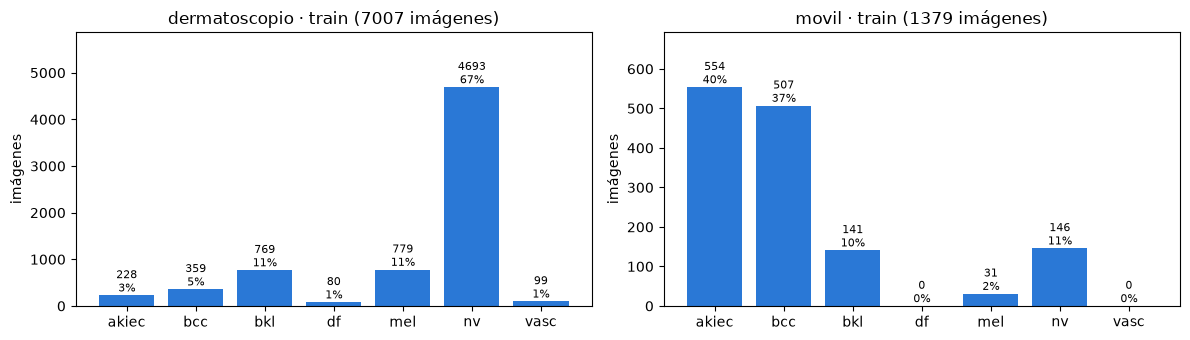

In [6]:
cod = clases['codigo']

# Recuento por dominio, partición y clase
display(pd.crosstab([tabla['dominio'], tabla['particion']], tabla['etiqueta'].map(cod), margins=True))

# Distribución de clases en el train de cada dominio (por separado: no se mezclan)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, dom in zip(axs, ['dermatoscopio', 'movil']):
    c = (tabla[(tabla['dominio'] == dom) & (tabla['particion'] == 'train')]['etiqueta']
         .value_counts().reindex(clases.index, fill_value=0))
    barras = ax.bar(cod, c.values, color='#2a78d6')
    ax.bar_label(barras, labels=[f'{v}\n{v / c.sum():.0%}' for v in c.values], fontsize=8)
    ax.set_title(f'{dom} · train ({c.sum()} imágenes)')
    ax.set_ylabel('imágenes'); ax.set_ylim(0, c.max() * 1.25)
    p = c[c > 0]
    print(f'{dom}: {cod[p.idxmax()]} es el {p.max() / p.sum():.0%} del train y tiene '
          f'{p.max() / p.min():.1f} veces más imágenes que {cod[p.idxmin()]}')
plt.tight_layout(); plt.show()

Recuentos por grupo:

particion,train,val,test,All
grupo,,,,
fototipo 1,101,29,23,153
fototipo 2,533,159,184,876
fototipo 3,214,90,88,392
fototipo 4,47,3,12,62
fototipo 5,7,2,1,10
fototipo 6,0,0,1,1
desconocido,477,177,150,804
All,1379,460,459,2298


Fototipo desconocido: 804 de 2298 fotos (35%)
Entre las fotos con fototipo, I–III son el 95%


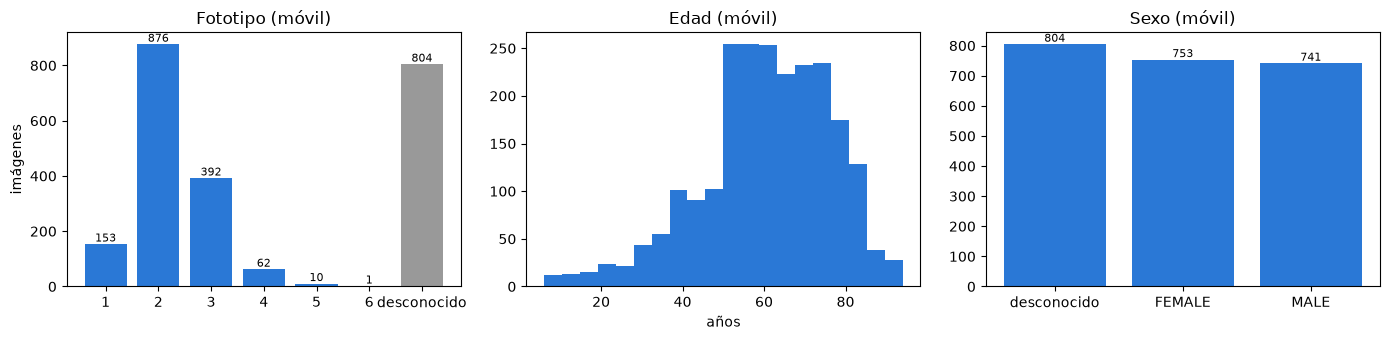

In [7]:
movil = tabla[tabla['dominio'] == 'movil']
orden = [f'fototipo {i}' for i in range(1, 7)] + ['desconocido']

# Fototipo (columna grupo) por partición: cuántas fotos de cada grupo habrá para evaluar
display(pd.crosstab(movil['grupo'], movil['particion'], margins=True)
        .reindex(index=orden + ['All'], columns=['train', 'val', 'test', 'All']).fillna(0).astype(int))

n = movil['grupo'].value_counts().reindex(orden, fill_value=0)
conocido = n.drop('desconocido')
print(f"Fototipo desconocido: {n['desconocido']} de {len(movil)} fotos ({n['desconocido'] / len(movil):.0%})")
print(f"Entre las fotos con fototipo, I–III son el {conocido.iloc[:3].sum() / conocido.sum():.0%}")

# Fototipo, edad y sexo en el destino (el origen no tiene estos datos)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
b = axs[0].bar([o.replace('fototipo ', '') for o in orden], n.values, color=['#2a78d6'] * 6 + ['#999999'])
axs[0].bar_label(b, fontsize=8); axs[0].set_title('Fototipo (móvil)'); axs[0].set_ylabel('imágenes')
axs[1].hist(movil['edad'].dropna(), bins=20, color='#2a78d6')
axs[1].set_title('Edad (móvil)'); axs[1].set_xlabel('años')
s = movil['sexo'].fillna('desconocido').value_counts()
b = axs[2].bar(s.index, s.values, color='#2a78d6'); axs[2].bar_label(b, fontsize=8); axs[2].set_title('Sexo (móvil)')
plt.tight_layout(); plt.show()

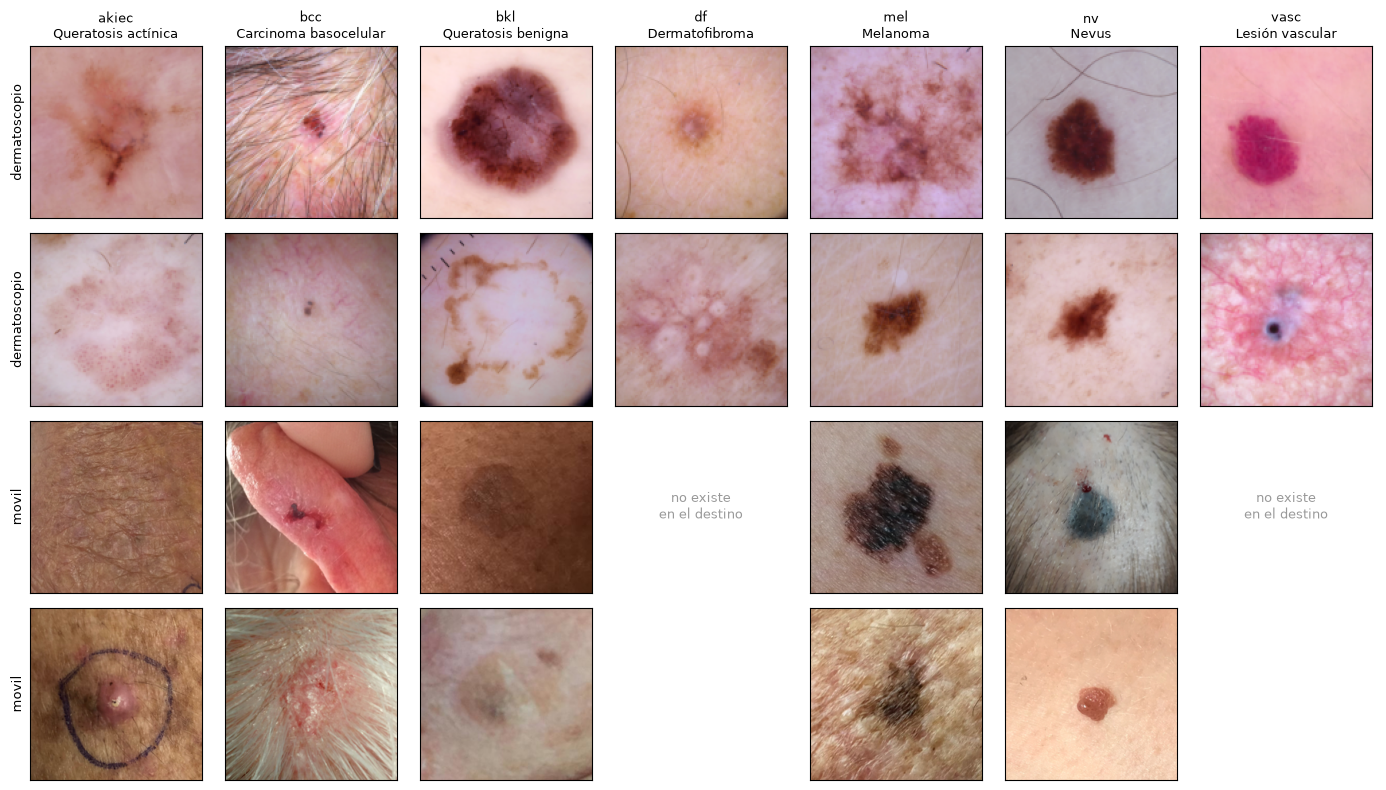

In [8]:
N_EJ = 2   # ejemplos por clase y dominio
doms = ['dermatoscopio', 'movil']
entreno = tabla[tabla['particion'] == 'train']

fig, axs = plt.subplots(len(doms) * N_EJ, len(clases), figsize=(2 * len(clases), 2 * len(doms) * N_EJ))
for d, dom in enumerate(doms):
    for et in clases.index:
        sub = entreno[(entreno['dominio'] == dom) & (entreno['etiqueta'] == et)]
        muestra = sub.sample(min(N_EJ, len(sub)), random_state=SEMILLA)
        for k in range(N_EJ):
            ax = axs[d * N_EJ + k, et]
            ax.set_xticks([]); ax.set_yticks([])
            if k < len(muestra):
                ax.imshow(Image.open(muestra.iloc[k]['ruta']))
            else:   # df y vasc no existen en el destino
                for s in ax.spines.values():
                    s.set_visible(False)
                if k == 0:
                    ax.text(.5, .5, 'no existe\nen el destino', ha='center', va='center',
                            fontsize=9, color='#999999', transform=ax.transAxes)
            if d == 0 and k == 0:
                ax.set_title(f"{clases.loc[et, 'codigo']}\n{clases.loc[et, 'nombre']}", fontsize=9)
            if et == 0:
                ax.set_ylabel(dom, fontsize=9)
plt.tight_layout(); plt.show()

## 3 · Extracción de características

**Teoría:** 3.3 · bloque 7 y 4.2 · bloque 6.

Cada imagen pasa **una vez** por cada modelo y se guarda su vector. Todo lo demás (U3, U4) trabaja con esos vectores, que es muy rápido. Si ya están calculadas, se cargan de `TRABAJO/features`.

In [ ]:
(TRABAJO / 'features').mkdir(exist_ok=True)
FEATS = {}
for nombre in MODELOS:
    fichero = TRABAJO / 'features' / f'{nombre}.pt'
    if fichero.exists() and torch.load(fichero)['rutas'] == tabla['ruta'].tolist():
        FEATS[nombre] = torch.load(fichero)['feats'].numpy()
    else:
        modelo, tf = cargar_modelo(nombre)
        feats = extraer(modelo, tf, tabla['ruta'])
        torch.save({'feats': feats, 'rutas': tabla['ruta'].tolist()}, fichero)
        FEATS[nombre] = feats.numpy()
    print(nombre, FEATS[nombre].shape)

## 4 · Clasificador lineal (*linear probe*)

**Teoría:** 3.2 · bloque 5 (un buen extractor + un clasificador simple).

Una capa lineal sobre las *features* estandarizadas. Equivale a una regresión logística, pero se entrena en GPU, que es más rápido. Es **la referencia que hay que batir** en U3 y U4.

In [ ]:
y = tabla['etiqueta'].to_numpy()

def mascara(dom, part):
    return ((tabla['dominio'] == dom) & (tabla['particion'] == part)).to_numpy()

# Se entrena SOLO con el train del dermatoscopio; el móvil solo se usa para evaluar
tr, va, te = (mascara('dermatoscopio', p) for p in ('train', 'val', 'test'))
va_d, te_d = mascara('movil', 'val'), mascara('movil', 'test')
EVAL = {('dermatoscopio', 'val'): va, ('dermatoscopio', 'test'): te,
        ('movil', 'val'): va_d, ('movil', 'test'): te_d}

def medir(y_true, pred, dominio):
    # En el móvil, la macro-F1 solo con las 5 clases que existen allí (df y vasc contarían como 0)
    labels = CLASES_DESTINO if dominio == 'movil' else None
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # aviso de balanced_acc por predecir df/vasc en el móvil: se ignoran bien
        return {'accuracy': accuracy_score(y_true, pred),
                'balanced_acc': balanced_accuracy_score(y_true, pred),
                'macro_f1': f1_score(y_true, pred, labels=labels, average='macro', zero_division=0)}

resultados, PRED_TEST, PRED_DESTINO, CABEZAS = [], {}, {}, {}
for nombre, X in FEATS.items():
    X_tr, *X_ev = estandarizar(X[tr], *(X[m] for m in EVAL.values()))   # escalador ajustado solo con el train del origen
    cabeza = entrenar_cabeza(X_tr, y[tr], len(clases))
    CABEZAS[nombre] = cabeza
    for ((dom, part), m), Xe in zip(EVAL.items(), X_ev):
        pred = predecir(cabeza, Xe)
        resultados.append({'modelo': nombre, 'dominio': dom, 'particion': part, **medir(y[m], pred, dom)})
        if part == 'test':
            (PRED_TEST if dom == 'dermatoscopio' else PRED_DESTINO)[nombre] = pred
resultados = pd.DataFrame(resultados)
display(resultados.round(3))

# Caída por cambio de dominio, en test
caida = resultados[resultados['particion'] == 'test'].pivot(index='modelo', columns='dominio', values='macro_f1')
caida['caída'] = caida['dermatoscopio'] - caida['movil']
print('Macro-F1 en test por dominio:')
display(caida.round(3))

,modelo,dominio,particion,accuracy,balanced_acc,macro_f1
0,resnet50,dermatoscopio,val,0.722,0.577,0.519
1,resnet50,dermatoscopio,test,0.724,0.552,0.513
2,resnet50,movil,val,0.222,0.315,0.219
3,resnet50,movil,test,0.255,0.281,0.232
4,dinov2_vits14,dermatoscopio,val,0.765,0.578,0.551
5,dinov2_vits14,dermatoscopio,test,0.768,0.637,0.629
6,dinov2_vits14,movil,val,0.333,0.306,0.242
7,dinov2_vits14,movil,test,0.309,0.320,0.237
8,clip_vitb32,dermatoscopio,val,0.795,0.650,0.632
9,clip_vitb32,dermatoscopio,test,0.771,0.643,0.613


Macro-F1 en test por dominio:


dominio,dermatoscopio,movil,caída
modelo,,,
clip_vitb32,0.613,0.169,0.444
dinov2_vits14,0.629,0.237,0.392
resnet50,0.513,0.232,0.282


## 5 · Evaluación

**Teoría:** 3.1 · bloque 1 (¿Cómo medirlo?).

Más allá de la *accuracy*: por clase, por grupo y dónde se confunde el modelo. El modelo se elige con **validación**; el test solo se mira al final.

,modelo,accuracy,balanced_acc,macro_f1
8,clip_vitb32,0.795,0.650,0.632
4,dinov2_vits14,0.765,0.578,0.551
0,resnet50,0.722,0.577,0.519


Mejor modelo en validación (dermatoscopio): clip_vitb32


,n_train,F1 dermatoscopio,F1 móvil
codigo,,,
akiec,228,0.50,0.01
bcc,359,0.61,0.20
bkl,769,0.61,0.20
df,80,0.41,NaN
mel,779,0.50,0.00
nv,4693,0.89,0.44
vasc,99,0.77,NaN


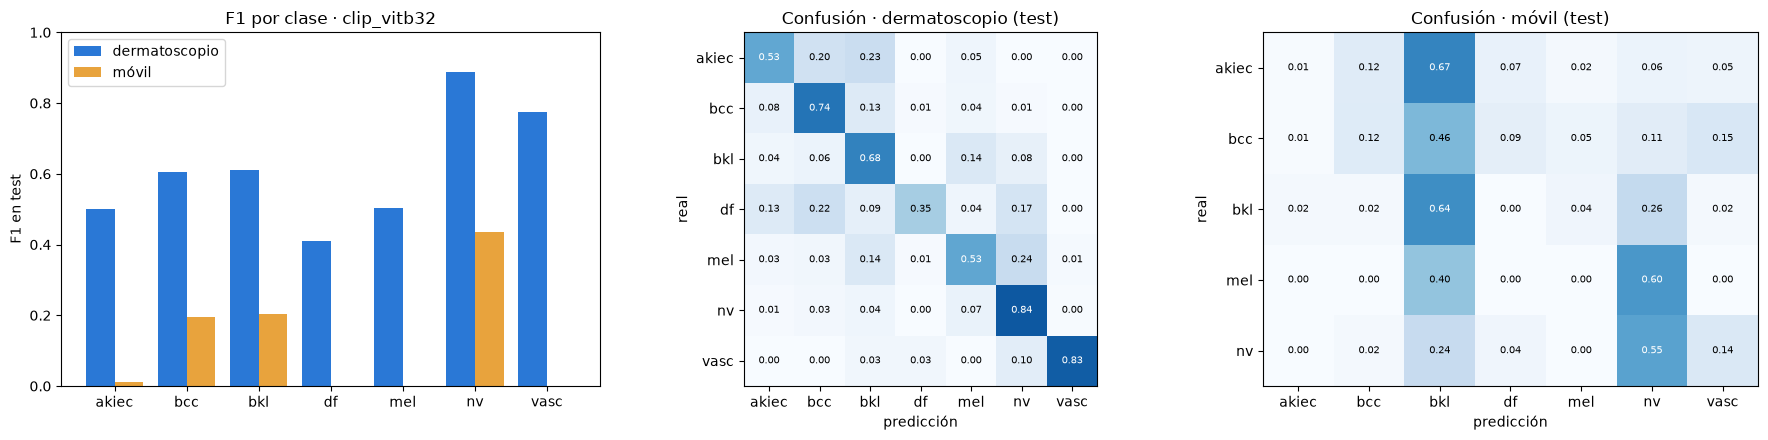

Peores clases en dermatoscopio: {'df': 0.41, 'akiec': 0.5, 'mel': 0.5}
Peores clases en móvil: {'mel': 0.0, 'akiec': 0.01, 'bcc': 0.2}


In [ ]:
from sklearn.metrics import confusion_matrix

# El modelo se elige con la validación del origen; el test solo se mira al final
val_o = resultados[(resultados['dominio'] == 'dermatoscopio') & (resultados['particion'] == 'val')]
MEJOR = val_o.sort_values('macro_f1').iloc[-1]['modelo']
display(val_o[['modelo', 'accuracy', 'balanced_acc', 'macro_f1']].sort_values('macro_f1', ascending=False).round(3))
print('Mejor modelo en validación (dermatoscopio):', MEJOR)
pred_o, pred_d = PRED_TEST[MEJOR], PRED_DESTINO[MEJOR]

# F1 por clase en los dos tests (en el móvil, df y vasc no existen: NaN)
f1_o = f1_score(y[te], pred_o, labels=clases.index, average=None, zero_division=0)
f1_d = f1_score(y[te_d], pred_d, labels=clases.index, average=None, zero_division=0)
f1_d = np.where(clases['en_destino'], f1_d, np.nan)
f1_clase = pd.DataFrame({'n_train': np.bincount(y[tr], minlength=len(clases)),
                         'F1 dermatoscopio': f1_o, 'F1 móvil': f1_d}, index=cod)
display(f1_clase.round(2))

def dibujar_confusion(ax, y_true, pred, filas, titulo):
    # Filas: clases reales presentes; columnas: las 7 clases que puede predecir el modelo
    cm = confusion_matrix(y_true, pred, labels=clases.index)[filas]
    cm = cm / cm.sum(1, keepdims=True)
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if cm[i, j] > .5 else 'black')
    ax.set_xticks(range(len(clases)), cod); ax.set_yticks(range(len(filas)), cod.loc[filas])
    ax.set_xlabel('predicción'); ax.set_ylabel('real'); ax.set_title(titulo)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(clases))
axs[0].bar(x - 0.2, f1_o, 0.4, label='dermatoscopio', color='#2a78d6')
axs[0].bar(x + 0.2, np.nan_to_num(f1_d), 0.4, label='móvil', color='#e8a33d')
axs[0].set_xticks(x, cod); axs[0].set_ylim(0, 1); axs[0].set_ylabel('F1 en test')
axs[0].set_title(f'F1 por clase · {MEJOR}'); axs[0].legend()
dibujar_confusion(axs[1], y[te], pred_o, list(clases.index), 'Confusión · dermatoscopio (test)')
dibujar_confusion(axs[2], y[te_d], pred_d, CLASES_DESTINO, 'Confusión · móvil (test)')
plt.tight_layout(); plt.show()

for dom, f in [('dermatoscopio', f1_clase['F1 dermatoscopio']), ('móvil', f1_clase['F1 móvil'])]:
    print(f'Peores clases en {dom}:', f.dropna().sort_values().head(3).round(2).to_dict())

,atributo,grupo,n,accuracy,balanced_acc,fiable
0,grupo,desconocido,150,0.253,0.390,True
1,grupo,fototipo 1,23,0.087,0.265,False
2,grupo,fototipo 2,184,0.141,0.305,True
3,grupo,fototipo 3,88,0.091,0.299,True
4,grupo,fototipo 4,12,0.250,0.100,False
5,grupo,fototipo 5,1,1.000,1.000,False
6,grupo,fototipo 6,1,1.000,1.000,False
7,edad_rango,<40,50,0.460,0.226,True
8,edad_rango,40–59,159,0.145,0.233,True
9,edad_rango,60–79,206,0.141,0.153,True


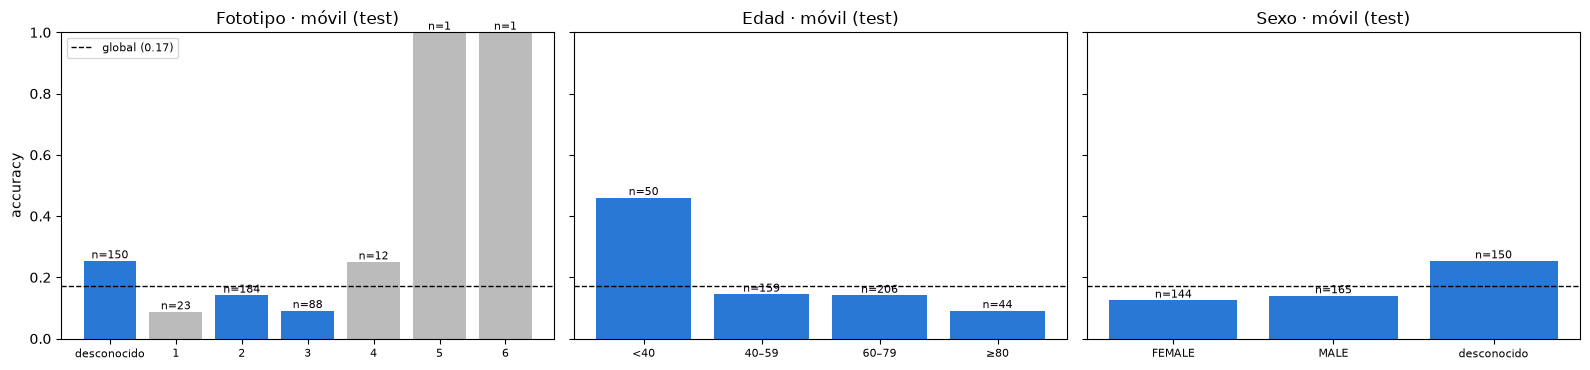

Fototipo: peor grupo fiable = fototipo 3 (0.09), mejor = desconocido (0.25), diferencia 0.16
Edad: peor grupo fiable = ≥80 (0.09), mejor = <40 (0.46), diferencia 0.37
Sexo: peor grupo fiable = FEMALE (0.12), mejor = desconocido (0.25), diferencia 0.13


In [ ]:
# Equidad: solo en el test del móvil (el dermatoscopio no tiene fototipo, edad ni sexo)
ev = tabla[te_d].copy()
ev['pred'] = pred_d
ev['acierto'] = ev['etiqueta'] == ev['pred']
ev['edad_rango'] = pd.cut(ev['edad'], [0, 40, 60, 80, 120], labels=['<40', '40–59', '60–79', '≥80'], right=False)
ev['sexo'] = ev['sexo'].fillna('desconocido')
MIN_N = 30   # por debajo, la métrica del grupo no es fiable

def por_grupo(col):
    filas = []
    for g, sub in ev.groupby(col, observed=True):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            filas.append({'atributo': col, 'grupo': str(g), 'n': len(sub), 'accuracy': sub['acierto'].mean(),
                          'balanced_acc': balanced_accuracy_score(sub['etiqueta'], sub['pred'])})
    return pd.DataFrame(filas)

ATRIBUTOS = {'grupo': 'Fototipo', 'edad_rango': 'Edad', 'sexo': 'Sexo'}
equidad = pd.concat([por_grupo(c) for c in ATRIBUTOS], ignore_index=True)
equidad['fiable'] = equidad['n'] >= MIN_N
display(equidad.round(3))

total = ev['acierto'].mean()
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (col, titulo) in zip(axs, ATRIBUTOS.items()):
    e = equidad[equidad['atributo'] == col]
    barras = ax.bar(e['grupo'].str.replace('fototipo ', ''), e['accuracy'],
                    color=np.where(e['fiable'], '#2a78d6', '#bbbbbb'))
    ax.bar_label(barras, labels=[f'n={n}' for n in e['n']], fontsize=8)
    ax.axhline(total, color='black', lw=1, ls='--', label=f'global ({total:.2f})')
    ax.set_title(f'{titulo} · móvil (test)'); ax.set_ylim(0, 1); ax.tick_params(axis='x', labelsize=8)
axs[0].set_ylabel('accuracy'); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

for col, titulo in ATRIBUTOS.items():
    e = equidad[(equidad['atributo'] == col) & equidad['fiable']]
    if len(e) >= 2:
        peor, mejor = e.loc[e['accuracy'].idxmin()], e.loc[e['accuracy'].idxmax()]
        print(f"{titulo}: peor grupo fiable = {peor['grupo']} ({peor['accuracy']:.2f}), "
              f"mejor = {mejor['grupo']} ({mejor['accuracy']:.2f}), diferencia {mejor['accuracy'] - peor['accuracy']:.2f}")
    else:
        print(f'{titulo}: menos de dos grupos con n ≥ {MIN_N}, no se puede comparar')

### 5.1 · Revisión: fototipos 5 y 6 y edad

Comentarios del profesorado sobre el baseline:
- ¿El 100 % de accuracy en los fototipos V y VI es casualidad o el modelo clasifica bien? Se miran las clases de esas imágenes y su reparto en train, val y test.
- ¿Cambian las clases según la edad? Se miran las lesiones por rango de edad y la accuracy por clase y edad.

Las figuras se guardan también en `memoria/images` para la memoria.

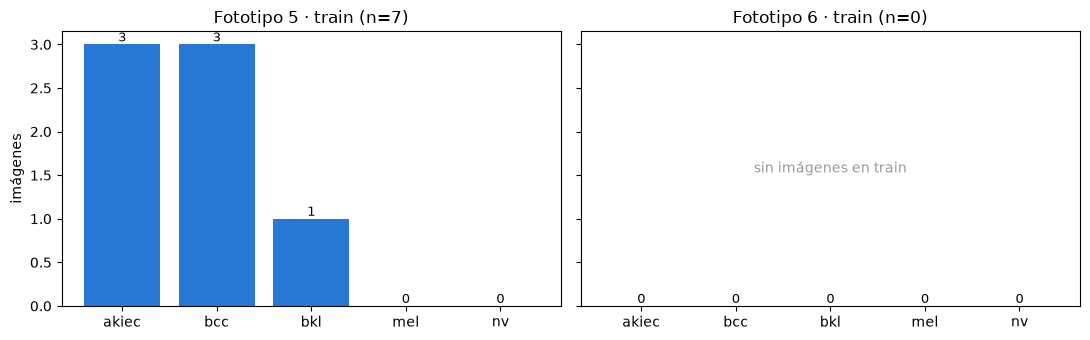

In [ ]:
IMG = Path('memoria/images'); IMG.mkdir(parents=True, exist_ok=True)
movil = tabla[tabla['dominio'] == 'movil'].copy()
movil['edad_rango'] = pd.cut(movil['edad'], [0, 40, 60, 80, 120], labels=['<40', '40–59', '60–79', '≥80'], right=False)
F56 = ['fototipo 5', 'fototipo 6']
clases_d = cod.loc[CLASES_DESTINO]

# Fototipos 5 y 6 en train: ¿qué clases tienen?
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, g in zip(axs, F56):
    c = (movil[(movil['grupo'] == g) & (movil['particion'] == 'train')]['etiqueta']
         .value_counts().reindex(CLASES_DESTINO, fill_value=0))
    b = ax.bar(clases_d, c.values, color='#2a78d6'); ax.bar_label(b, fontsize=9)
    ax.set_title(f'{g.capitalize()} · train (n={c.sum()})')
    if c.sum() == 0:
        ax.text(.5, .5, 'sin imágenes en train', ha='center', va='center', color='#999999', transform=ax.transAxes)
axs[0].set_ylabel('imágenes')
plt.tight_layout(); plt.savefig(IMG / 'revision_fototipos56_train.png', dpi=200, bbox_inches='tight'); plt.show()

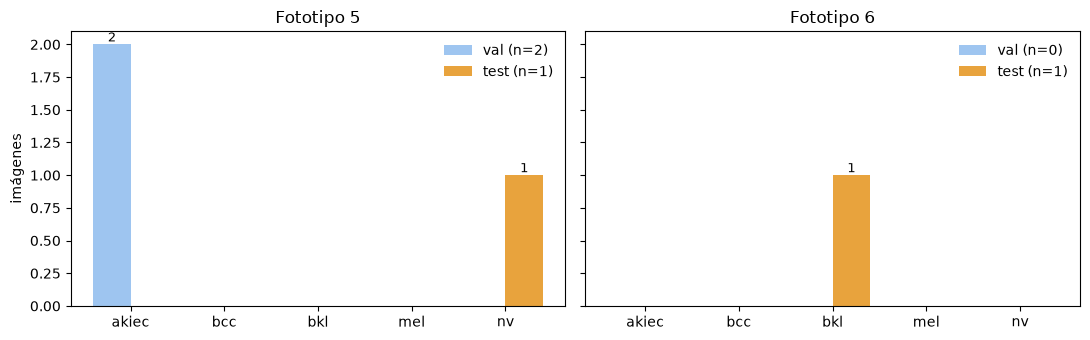

,grupo,real,predicción,acierto
10877,fototipo 6,bkl,bkl,True
11218,fototipo 5,nv,nv,True


Predicciones del modelo en todo el test del móvil (%):
{'bkl': 53.8, 'nv': 16.3, 'bcc': 9.8, 'vasc': 9.4, 'df': 6.8, 'mel': 3.3, 'akiec': 0.7}


In [ ]:
# Fototipos 5 y 6 en val y test, y si las imágenes de test se aciertan
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
x = np.arange(len(CLASES_DESTINO))
for ax, g in zip(axs, F56):
    for k, (part, color) in enumerate([('val', '#9ec5f0'), ('test', '#e8a33d')]):
        c = (movil[(movil['grupo'] == g) & (movil['particion'] == part)]['etiqueta']
             .value_counts().reindex(CLASES_DESTINO, fill_value=0))
        b = ax.bar(x + (k - .5) * .4, c.values, .4, color=color, label=f'{part} (n={c.sum()})')
        ax.bar_label(b, labels=[v if v else '' for v in c.values], fontsize=9)
    ax.set_xticks(x, clases_d); ax.set_title(g.capitalize()); ax.legend(frameon=False)
axs[0].set_ylabel('imágenes')
plt.tight_layout(); plt.savefig(IMG / 'revision_fototipos56_val_test.png', dpi=200, bbox_inches='tight'); plt.show()

casos = ev[ev['grupo'].isin(F56)][['grupo', 'etiqueta', 'pred', 'acierto']].copy()
casos['etiqueta'] = casos['etiqueta'].map(cod); casos['pred'] = casos['pred'].map(cod)
display(casos.rename(columns={'etiqueta': 'real', 'pred': 'predicción'}))
print('Predicciones del modelo en todo el test del móvil (%):')
print((pd.Series(pred_d).map(cod).value_counts(normalize=True) * 100).round(1).to_dict())

codigo,akiec,bcc,bkl,mel,nv
edad_rango,,,,,
<40,34,40,8,2,159
40–59,322,311,60,27,69
60–79,470,394,137,19,15
≥80,96,100,30,4,1


/var/folders/65/r55xnbt14k5fgbrtf11p9g4m0000gp/T/ipykernel_70160/1558393951.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct.div(ct.sum(1), axis=0).plot.bar(stacked=True, ax=axs[1], rot=0, color=colores, legend=False)


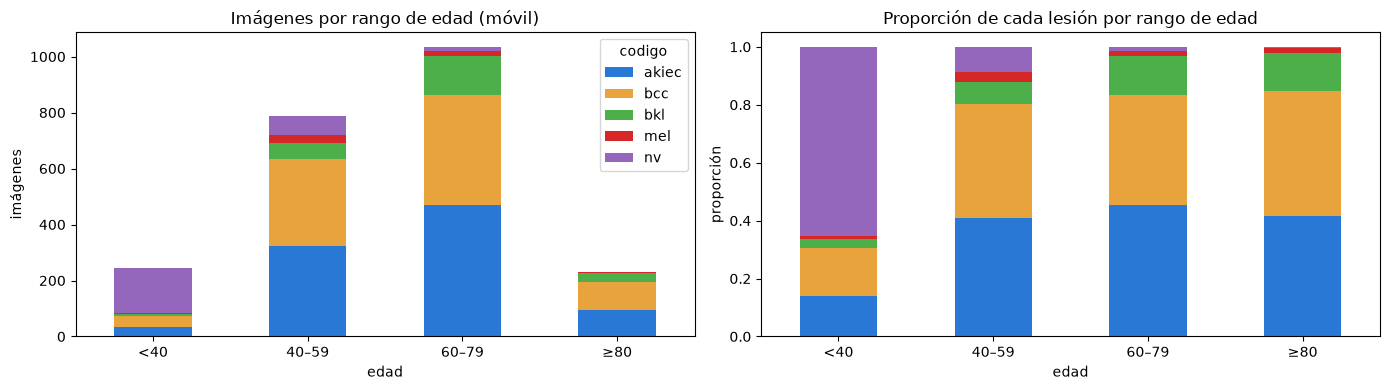

In [ ]:
# Tipos de lesión por rango de edad (todas las fotos del móvil)
ct = pd.crosstab(movil['edad_rango'], movil['etiqueta'].map(cod)).reindex(columns=clases_d, fill_value=0)
display(ct)
colores = dict(zip(clases_d, ['#2a78d6', '#e8a33d', '#4daf4a', '#d62728', '#9467bd']))
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
ct.plot.bar(stacked=True, ax=axs[0], rot=0, color=colores)
axs[0].set_title('Imágenes por rango de edad (móvil)'); axs[0].set_ylabel('imágenes'); axs[0].set_xlabel('edad')
ct.div(ct.sum(1), axis=0).plot.bar(stacked=True, ax=axs[1], rot=0, color=colores, legend=False)
axs[1].set_title('Proporción de cada lesión por rango de edad'); axs[1].set_ylabel('proporción'); axs[1].set_xlabel('edad')
plt.tight_layout(); plt.savefig(IMG / 'revision_lesiones_por_edad.png', dpi=200, bbox_inches='tight'); plt.show()

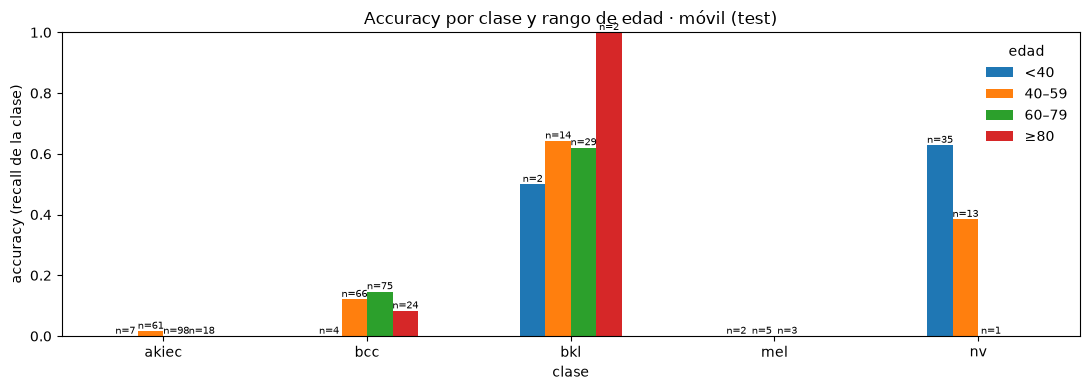

In [ ]:
# Accuracy por clase y rango de edad en el test del móvil (el gráfico que pide el comentario)
acc = (ev.assign(clase=ev['etiqueta'].map(cod))
         .groupby(['clase', 'edad_rango'], observed=False)['acierto'].agg(['mean', 'size']).reset_index())
piv = acc.pivot(index='clase', columns='edad_rango', values='mean').reindex(clases_d)
n = acc.pivot(index='clase', columns='edad_rango', values='size').reindex(clases_d)
ax = piv.plot.bar(rot=0, figsize=(11, 4))
for cont, col in zip(ax.containers, n.columns):
    ax.bar_label(cont, labels=[f'n={int(v)}' if v else '' for v in n[col].fillna(0)], fontsize=7)
ax.set_ylabel('accuracy (recall de la clase)'); ax.set_xlabel('clase'); ax.set_ylim(0, 1)
ax.set_title('Accuracy por clase y rango de edad · móvil (test)'); ax.legend(title='edad', frameon=False)
plt.tight_layout(); plt.savefig(IMG / 'revision_accuracy_clase_edad.png', dpi=200, bbox_inches='tight'); plt.show()

## 6 · Análisis preliminar

Lo que dicen estos resultados de cara a las unidades siguientes, en el ejemplo de las señales de tráfico:

- **¿Hay datos suficientes?** Sí en conjunto (unas 22 500 imágenes de entrenamiento), pero repartidas en 43 clases y en pistas de unas 30 fotos casi iguales: hay menos variedad de la que parece.
- **¿Están desbalanceados?** Sí: la clase más grande tiene unas 10 veces más imágenes que la más pequeña, y la *balanced accuracy* queda varios puntos por debajo de la *accuracy*. Las clases con peor F1 son de las pequeñas y se confunden con señales parecidas (giros, curvas). Es el primer candidato para U3.
- **¿Qué modelo preentrenado funciona mejor?** CLIP, con diferencia. DINOv2 queda por debajo de ResNet-50: merece la pena entender por qué en U3 (comparar preentrenamientos).
- **¿Hay grupos que funcionen peor?** Las señales de peligro y las de fin de restricción, que son las más parecidas entre sí.
- **¿Hay varios dominios?** No: todo son fotos del mismo tipo. Para U4 habrá que justificar un destino (por ejemplo, niebla o noche, que en un coche sí son cambios realistas).
- **¿Es un tema sensible?** No hay personas ni datos personales. En temas con personas o con salud, decidlo aquí y tenedlo en cuenta en U5.

## 7 · Guardar

La tabla, las clases y las *features* ya están en `TRABAJO`. Guardamos también el resumen.

In [ ]:
# Clases (la columna pad se guarda como texto 'ACK;SCC' para poder leerla en U3/U4)
clases.assign(pad=clases['pad'].str.join(';')).to_csv(TRABAJO / 'clases.csv')

resultados.to_csv(TRABAJO / 'resultados_baseline.csv', index=False)          # métricas por modelo, dominio y partición
f1_clase.to_csv(TRABAJO / 'f1_por_clase_baseline.csv')                      # F1 por clase del mejor modelo
equidad.to_csv(TRABAJO / 'equidad_baseline.csv', index=False)               # métricas por grupo (móvil)
pd.Series({'mejor_modelo': MEJOR}).to_json(TRABAJO / 'baseline.json')       # qué modelo usar de referencia en U3/U4

print(sorted(str(p.relative_to(TRABAJO)) for p in TRABAJO.rglob('*') if p.is_file()))

['baseline.json', 'clases.csv', 'equidad_baseline.csv', 'f1_por_clase_baseline.csv', 'features/clip_vitb32.pt', 'features/dinov2_vits14.pt', 'features/resnet50.pt', 'resultados_baseline.csv', 'tabla.csv']
